In [2]:
import os

os.chdir(r"C:\Users\SIRI\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales")

In [3]:
os.getcwd()

'C:\\Users\\SIRI\\Desktop\\OIBSIP\\DataAnalytics-L1-EDARetailSales'

In [4]:
os.listdir()

['retail_sales_dataset.csv']

In [5]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
df.shape

(1000, 9)

In [7]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [8]:
df.dtypes

Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

In [9]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.select_dtypes(include="number").columns

Index(['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'], dtype='object')

In [12]:
df.mean(numeric_only=True)

Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

In [13]:
df.median(numeric_only=True)

Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

In [14]:
df.mode(numeric_only=True)

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
0,1,43.0,4.0,50.0,50.0
1,2,64.0,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN
3,4,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN
...,...,...,...,...,...
995,996,NaN,NaN,NaN,NaN
996,997,NaN,NaN,NaN,NaN
997,998,NaN,NaN,NaN,NaN
998,999,NaN,NaN,NaN,NaN


In [15]:
df.std(numeric_only=True)

Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

In [16]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [17]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [19]:
df['Date'] = pd.to_datetime(df['Date'])

In [20]:
df.dtypes

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [21]:
df['Month'] = df['Date'].dt.month

In [22]:
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum()

monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [23]:
import matplotlib.pyplot as plt

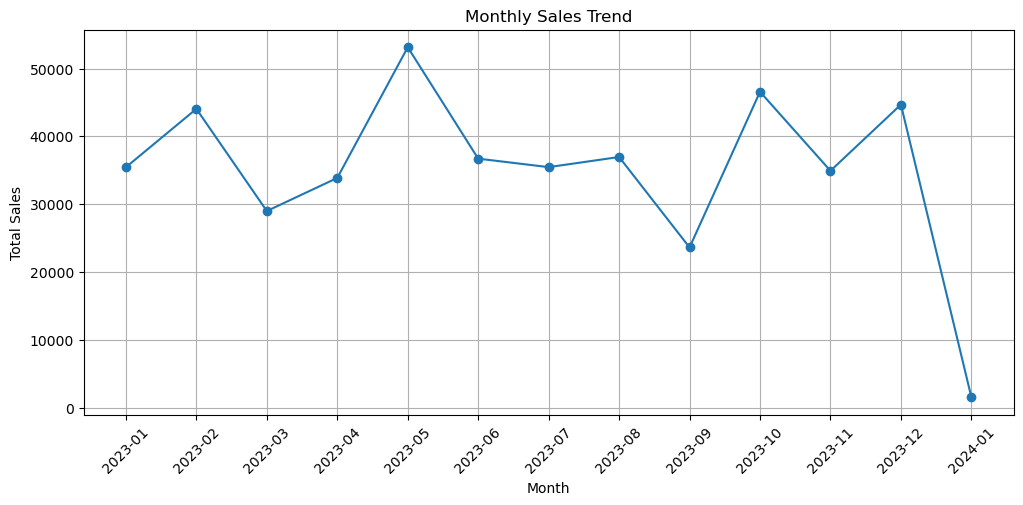

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [25]:
quarterly_sales = df.groupby(
    df['Date'].dt.to_period('Q')
)['Total Amount'].sum()

quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

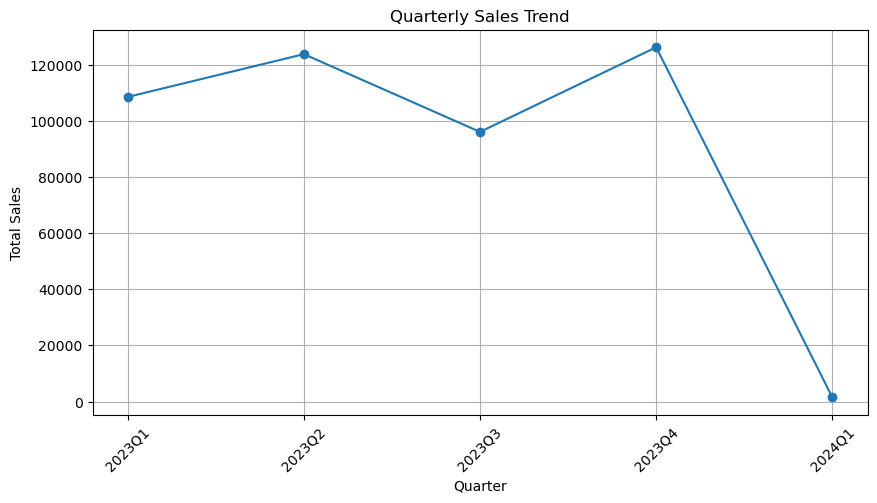

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(quarterly_sales.index.astype(str),
         quarterly_sales.values,
         marker='o')

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [27]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'Month'],
      dtype='object')

In [28]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '20-30', '31-40', '41-50', '51-60', 'Above 60']
)

In [29]:
age_group_counts = df['Age Group'].value_counts().sort_index()

age_group_counts

Age Group
Below 20     63
20-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64

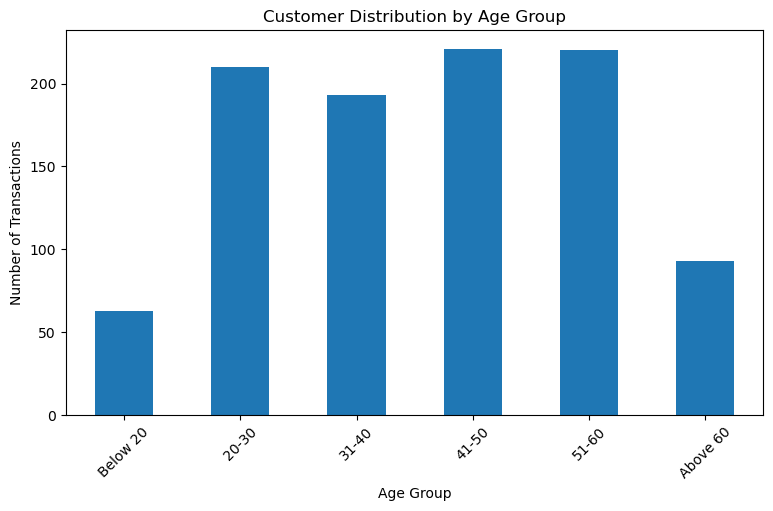

In [30]:
import matplotlib.pyplot as plt

age_group_counts.plot(kind='bar', figsize=(9, 5))

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.show()

In [31]:
gender_counts = df['Gender'].value_counts()

gender_counts

Gender
Female    510
Male      490
Name: count, dtype: int64

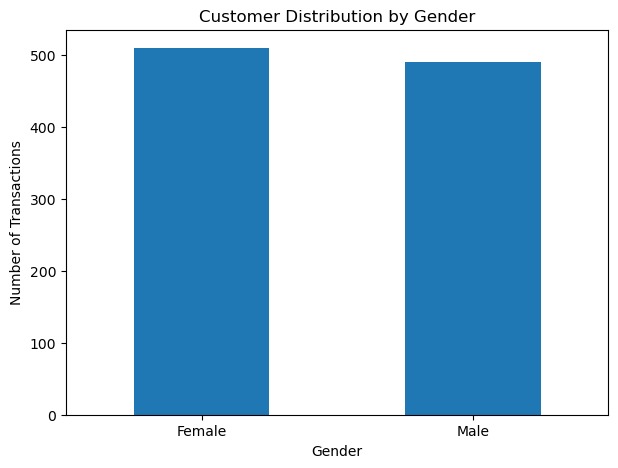

In [32]:
gender_counts.plot(kind='bar', figsize=(7, 5))

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

In [33]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

gender_sales

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

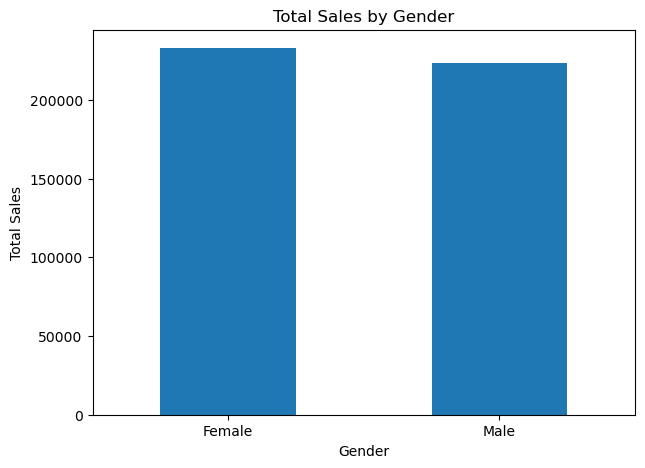

In [34]:
gender_sales.plot(kind='bar', figsize=(7, 5))

plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [35]:
age_group_sales = df.groupby(
    'Age Group', observed=False
)['Total Amount'].sum()

age_group_sales

Age Group
Below 20     34730
20-30        98215
31-40        95950
41-50        93795
51-60       100085
Above 60     33225
Name: Total Amount, dtype: int64

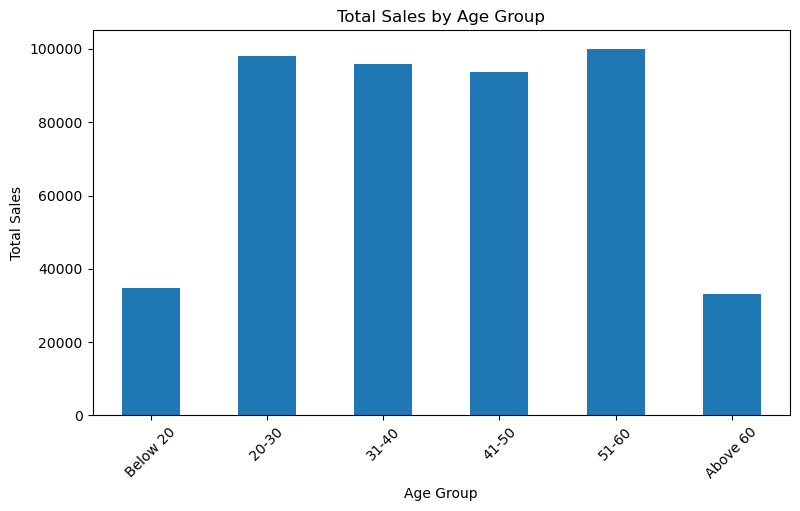

In [36]:
age_group_sales.plot(kind='bar', figsize=(9, 5))

plt.title('Total Sales by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [37]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'Month', 'Age Group'],
      dtype='object')

In [39]:
top_products = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False).head(10)

top_products

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

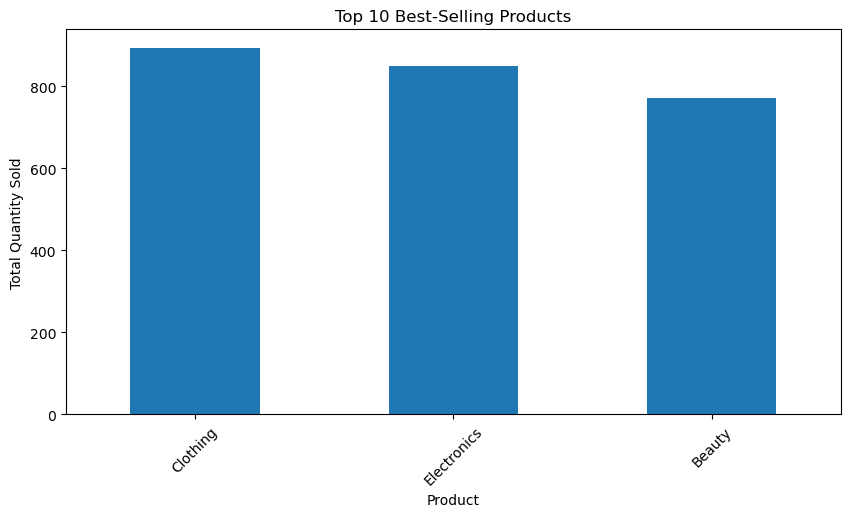

In [40]:
top_products.plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Product')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.show()

In [41]:
category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

category_sales

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

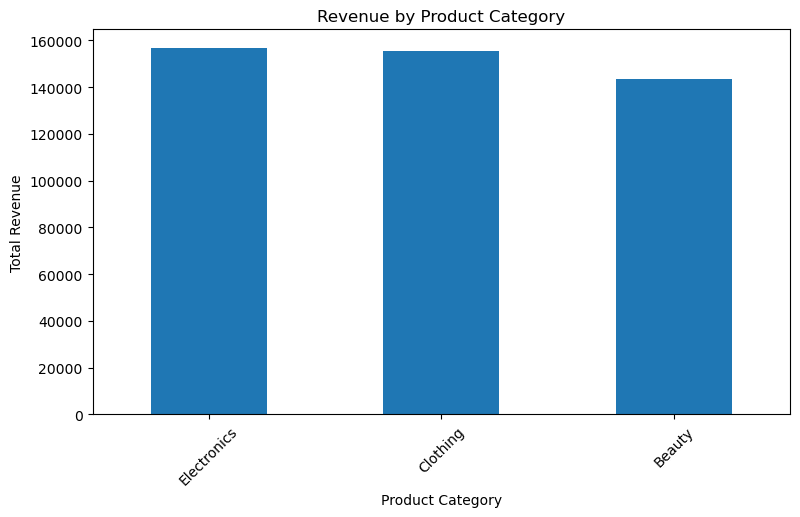

In [42]:
category_sales.plot(kind='bar', figsize=(9, 5))

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

In [43]:
category_sales.idxmax()

'Electronics'

In [44]:
category_sales.max()

156905

In [45]:
numeric_df = df.select_dtypes(include='number')

In [46]:
numeric_df.head()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount,Month
0,1,34,3,50,150,11
1,2,26,2,500,1000,2
2,3,50,1,30,30,1
3,4,37,1,500,500,5
4,5,30,2,50,100,5


In [47]:
numeric_df = numeric_df.drop(columns=['Transaction ID'], errors='ignore')

In [48]:
correlation = numeric_df.corr()

correlation

,Age,Quantity,Price per Unit,Total Amount,Month
Age,1.000000,-0.023737,-0.038423,-0.060568,-0.000640
Quantity,-0.023737,1.000000,0.017501,0.373707,-0.021803
Price per Unit,-0.038423,0.017501,1.000000,0.851925,-0.008161
Total Amount,-0.060568,0.373707,0.851925,1.000000,-0.005197
Month,-0.000640,-0.021803,-0.008161,-0.005197,1.000000


In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

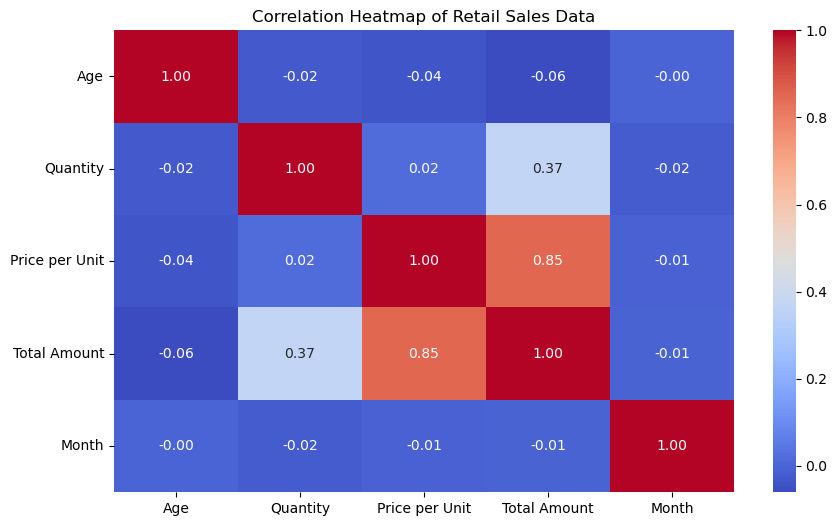

In [51]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Retail Sales Data')
plt.show()

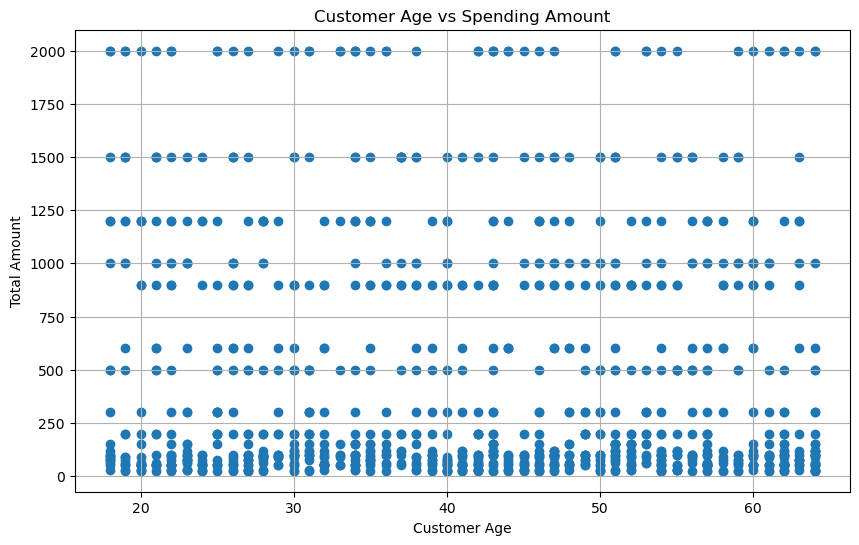

In [52]:
plt.figure(figsize=(10, 6))

plt.scatter(df['Age'], df['Total Amount'])

plt.title('Customer Age vs Spending Amount')
plt.xlabel('Customer Age')
plt.ylabel('Total Amount')
plt.grid(True)

plt.show()

In [53]:
age_spending = df.groupby('Age Group', observed=False)['Total Amount'].mean()

age_spending

Age Group
Below 20    551.269841
20-30       467.690476
31-40       497.150259
41-50       424.411765
51-60       454.931818
Above 60    357.258065
Name: Total Amount, dtype: float64

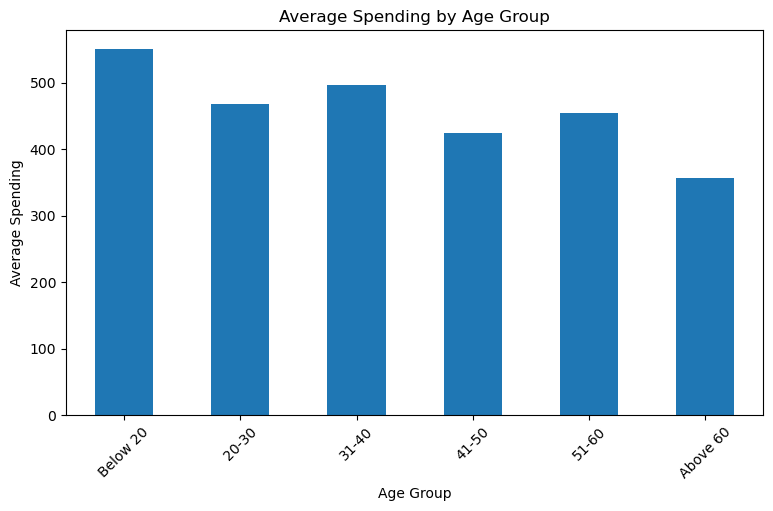

In [54]:
age_spending.plot(kind='bar', figsize=(9, 5))

plt.title('Average Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Spending')
plt.xticks(rotation=45)

plt.show()

Conclusion

The exploratory data analysis was performed on the retail sales dataset using Python, Pandas, Matplotlib, and Seaborn. The analysis helped understand sales trends, customer demographics, product/category performance, and customer spending patterns. Monthly and quarterly sales trends were analyzed, along with age groups and gender. Correlation analysis was also performed to understand relationships between numerical variables.

Overall, the analysis provides useful insights that can help a business understand its customers, monitor sales performance, improve inventory planning, and make better marketing decisions.

## Business Recommendations

1. **Targeted Marketing:** Use customer demographic information such as age and gender to create more targeted marketing campaigns.

2. **Inventory Planning:** Maintain sufficient inventory for high-performing products or categories based on the sales analysis.

3. **Sales Promotions:** Use monthly and quarterly sales trends to plan promotional campaigns during periods of lower sales.

4. **Improve Low-Performing Categories:** Identify categories with lower sales and use suitable discounts, promotions, and marketing strategies to improve their performance.